In [304]:
import sys
import os
import jax

jax.config.update("jax_platform_name", "cpu")

print(jax.default_backend())
print(jax.devices())

# Add `pyspect/src` to path when running from `pyspect/hjb_mpc`.
parent_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
# src_path = os.path.join(parent_dir, "src")

src_path = "/home/veronica/Projects/pyspect/src"
if src_path not in sys.path:
    sys.path.append(src_path)

from functools import reduce
from math import pi
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from pyspect import *
from pyspect.primitives import *
from pyspect.tlt import *
from pyspect.set_builder import *

TLT.select(ContLTL)


cpu
[CpuDevice(id=0)]


In [305]:
# Map bounds: [0, 4] x [0, 4]
X0, XN = 0.0, 4.0
Y0, YN = 0.0, 4.0

dt = 0.2

# Obstacle 1: lower-left 2x2 square
lower_obs_x, lower_obs_y = 0.0, 0.0
lower_obs_w, lower_obs_h = 2.0, 2.0

# Obstacle 2: top corridor block, 2.8 long and 0.2 wide
upper_obs_x, upper_obs_y = 1.2, 2.8
upper_obs_w, upper_obs_h = 2.8, 0.4

# Goal region in the upper-right corner
goal_x, goal_y = 3.58, 3.46
goal_w, goal_h = 0.30, 0.36
target_set = BoundedSet(x=(goal_x, goal_x + goal_w), y=(goal_y, goal_y + goal_h))

# Car start: [x, y, yaw, delta, vel]
car_w, car_h = 0.25, 0.40
STATE_INIT = np.array([3.00, 0.32, pi / 2, 0.0, 0.5])
print("STATE_INIT:", STATE_INIT)

# Keep map bounds slightly inside domain
map_box = BoundedSet(x=(X0 + 0.01, X0 + XN - 0.01), y=(Y0 + 0.01, Y0 + YN - 0.01))
lower_obstacle = AND(
    AND(map_box, BoundedSet(x=(..., lower_obs_x + lower_obs_w))),
    BoundedSet(y=(..., lower_obs_y + lower_obs_h)),
)
upper_obstacle = AND(
    AND(map_box, BoundedSet(x=(upper_obs_x, ...))),
    BoundedSet(y=(upper_obs_y, upper_obs_y + upper_obs_h)),
)
obstacles = OR(lower_obstacle, upper_obstacle)

safe_region_static = AND(map_box, NOT(obstacles))

print(f"Lower obstacle: x=({lower_obs_x}, {lower_obs_x + lower_obs_w}), y=({lower_obs_y}, {lower_obs_y + lower_obs_h})")
print(f"Upper obstacle: x=({upper_obs_x}, {upper_obs_x + upper_obs_w}), y=({upper_obs_y}, {upper_obs_y + upper_obs_h})")
print(f"Goal region: x=({goal_x}, {goal_x + goal_w}), y=({goal_y}, {goal_y + goal_h})")


STATE_INIT: [3.         0.32       1.57079633 0.         0.5       ]
Lower obstacle: x=(0.0, 2.0), y=(0.0, 2.0)
Upper obstacle: x=(1.2, 4.0), y=(2.8, 3.1999999999999997)
Goal region: x=(3.58, 3.88), y=(3.46, 3.82)


/tmp/ipykernel_1937881/2885834088.py:18: DeprecationWarning: Call to deprecated class BoundedSet. (BoundedSet is renamed to AlignedBoxSet for clarity, please use AlignedBoxSet instead of BoundedSet.)
  target_set = BoundedSet(x=(goal_x, goal_x + goal_w), y=(goal_y, goal_y + goal_h))
/tmp/ipykernel_1937881/2885834088.py:26: DeprecationWarning: Call to deprecated class BoundedSet. (BoundedSet is renamed to AlignedBoxSet for clarity, please use AlignedBoxSet instead of BoundedSet.)
  map_box = BoundedSet(x=(X0 + 0.01, X0 + XN - 0.01), y=(Y0 + 0.01, Y0 + YN - 0.01))
/tmp/ipykernel_1937881/2885834088.py:28: DeprecationWarning: Call to deprecated class BoundedSet. (BoundedSet is renamed to AlignedBoxSet for clarity, please use AlignedBoxSet instead of BoundedSet.)
  AND(map_box, BoundedSet(x=(..., lower_obs_x + lower_obs_w))),
/tmp/ipykernel_1937881/2885834088.py:29: DeprecationWarning: Call to deprecated class BoundedSet. (BoundedSet is renamed to AlignedBoxSet for clarity, please use Align

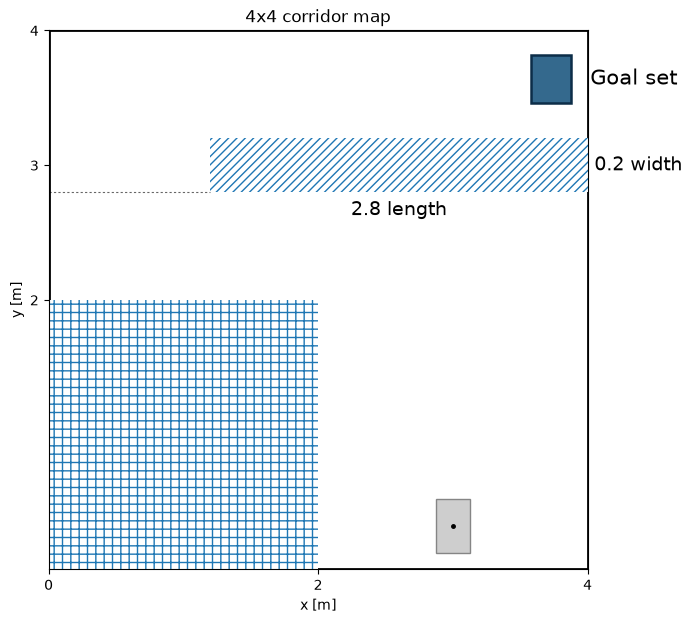

In [306]:
from matplotlib.patches import Rectangle
from matplotlib.transforms import Affine2D

fig, ax = plt.subplots(figsize=(7, 7))

# Workspace square
ax.add_patch(Rectangle((X0, Y0), XN, YN, fill=False, lw=2, edgecolor="black"))

# Obstacles
ax.add_patch(Rectangle((lower_obs_x, lower_obs_y), lower_obs_w, lower_obs_h, facecolor="white", edgecolor="tab:blue", hatch="++", linewidth=0.0, label="Obstacle"))
ax.add_patch(Rectangle((upper_obs_x, upper_obs_y), upper_obs_w, upper_obs_h, facecolor="white", edgecolor="tab:blue", hatch="////", linewidth=0.0))

# Goal set
ax.add_patch(Rectangle((goal_x, goal_y), goal_w, goal_h, facecolor="#34698d", edgecolor="#0c2d48", linewidth=1.8, label="Goal set"))

# Car pose
heading_deg = np.degrees(STATE_INIT[2])
car_rect = Rectangle((-car_h / 2, -car_w / 2), car_h, car_w, facecolor="0.8", edgecolor="0.5", alpha=0.95, linewidth=1.0, label="Car")
t = Affine2D().rotate_deg(heading_deg).translate(STATE_INIT[0], STATE_INIT[1]) + ax.transData
car_rect.set_transform(t)
ax.add_patch(car_rect)
ax.plot(STATE_INIT[0], STATE_INIT[1], "ko", markersize=2.5)

# Figure annotations
ax.hlines(upper_obs_y, X0, upper_obs_x, colors="k", linestyles=(0, (2, 2)), linewidth=0.8, alpha=0.6)
ax.text(upper_obs_x + upper_obs_w / 2, upper_obs_y - 0.06, "2.8 length", ha="center", va="top", fontsize=14)
ax.text(upper_obs_x + upper_obs_w + 0.05, upper_obs_y + upper_obs_h / 2, "0.2 width", ha="left", va="center", fontsize=14)
ax.text(goal_x + goal_w + 0.14, goal_y + goal_h / 2, "Goal set", ha="left", va="center", fontsize=15)

ax.set_xlim(X0, X0 + XN)
ax.set_ylim(Y0, Y0 + YN)
ax.set_aspect("equal", adjustable="box")
ax.set_title("4x4 corridor map")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_xticks([0, 2, 4])
ax.set_yticks([2, 3, 4])
ax.grid(False)
plt.show()


In [307]:
# def FollowTo(constraint, goal_or_constraint, *more):
#     if more: # 2nd arg is constraint
#         return FollowTo(And(constraint, goal_or_constraint), *more)
#     else: # 2nd arg is exit
#         return Until(constraint, goal_or_constraint)

vehicle_1 = UNTIL(safe_region_static, target_set)
# print(vehicle_1)

In [308]:
from pyspect.systems.hj_reachability.bicycle4d import Bicycle4D
from pyspect.impls.hj_reachability import TVHJImpl
from pyspect.plotting.levelsets import plot3D_levelset

jax.config.update("jax_platform_name", "cpu")

t_max = 12

# Steering limits [rad] and acceleration limits [m/s²]
max_steer = 0.7
max_steer_rate = np.pi
max_accel = 0.4
max_vel   = 0.8

time_points = int(t_max/dt + 1)
impl = TVHJImpl(
    dynamics=dict(
        cls=Bicycle4D,
        min_steer=-max_steer,
        max_steer=max_steer,
        min_accel=-max_accel,
        max_accel=max_accel,
        wheelbase=0.32,
    ),
    axis_specs=[
        dict(name='t',      bounds=[0, t_max],           points=time_points),
        dict(name='x',      bounds=[X0, X0 + XN],        points=25),
        dict(name='y',      bounds=[Y0, Y0 + YN],        points=25),
        dict(name='*yaw',   bounds=[-pi, pi],             points=15),
        dict(name='vel',    bounds=[0.0, max_vel],        points=11),
    ],
)

In [309]:
print(jax.default_backend())
print(jax.devices())

out1 = TLT.construct(vehicle_1).realize(impl)
print("BRT shape:", out1.shape)

np.save("out_bicycle5d.npy", np.asarray(out1))
print("Saved")


cpu
[CpuDevice(id=0)]


Running for 60 iterations:   0%|          | 0/60 [00:00<?, ?it/s]

BRT shape: (61, 25, 25, 15, 11)
Saved


In [317]:
t_pred = 12.0
time_grid_long = np.array(impl.timeline)
idx_tb = int(np.argmin(np.abs(time_grid_long - t_pred)))
print(f"Index of t_b = {t_pred}s: {idx_tb} over {len(time_grid_long) - 1}")

v_terminal_4d = np.asarray(out1)[idx_tb, ...]
print("v_terminal_4d shape:", v_terminal_4d.shape)

Index of t_b = 12.0s: 60 over 60
v_terminal_4d shape: (25, 25, 15, 11)


In [318]:
# # Forward being in direction of y
# _v = .3 # moving obstacle speed
# _w = .4 # moving obstacle width
# _x = 2.0 # moving obstacle center x
# moving_obstacle_boundary = BoundedSet(x=(_x-_w/2, _x+_w/2), y=(3., ...))
# moving_obstacle = EMPTY
# for i, t in enumerate([0.0]):
#     __v = +_v if i % 2 == 0 else -_v
#     __t = t + 0.5 if i % 2 == 0 else t - 0.5
#     infront_moving_obstacle = HalfSpaceSet(normal=[ +1, -__v],
#                                            offset=[3.5,    t],
#                                            axes = ['y',  't'])

#     behind_moving_obstacle = HalfSpaceSet(normal=[ -1, +__v],
#                                           offset=[3.0,  __t],
#                                           axes = ['y',  't'])
#     moving_obstacle = Union(moving_obstacle, reduce(Inter, [
#         Compl(infront_moving_obstacle), 
#         Compl(behind_moving_obstacle),
#         moving_obstacle_boundary,
#     ]))

def build_moving_obstacle_short(t_start, duration):
    _v = 0.3
    _w = 0.4
    _x = 2.0
    moving_obstacle_boundary = BoundedSet(x=(_x - _w/2, _x + _w/2), y=(3.0, ...))
    
    sim_time_points = [0.0, 5.0,10.0, 15.0, 20.0]
    
    short_obs = EMPTY
    for i, t_sim in enumerate(sim_time_points):
        t_loc = t_sim - t_start
        
        if -1.0 <= t_loc <= duration + 1.0:
            __v = +_v if i % 2 == 0 else -_v
            
            __t_sim = t_sim + 0.5 if i % 2 == 0 else t_sim - 0.5
            __t_loc = __t_sim - t_start
            
            t_loc_clamped = np.clip(t_loc, 0.0, duration)
            __t_loc_clamped = np.clip(__t_loc, 0.0, duration)
            
            infront = HalfSpaceSet(normal=[+1, -__v], offset=[3.5, t_loc_clamped], axes=['y', 't'])
            behind  = HalfSpaceSet(normal=[-1, +__v], offset=[3.0, __t_loc_clamped], axes=['y', 't'])
            
            segment = reduce(Inter, [
                Compl(infront),
                Compl(behind),
                moving_obstacle_boundary,
            ])
            short_obs = Union(short_obs, segment)
            
    return short_obs


moving_obstacle = build_moving_obstacle_short(t_start=0.0, duration=t_pred)

safe_region_short = AND(safe_region_static, NOT(moving_obstacle))
target_short = Set(v_terminal_4d)
task_short = UNTIL(safe_region_short, target_short)

/tmp/ipykernel_1937881/1954858886.py:27: DeprecationWarning: Call to deprecated class BoundedSet. (BoundedSet is renamed to AlignedBoxSet for clarity, please use AlignedBoxSet instead of BoundedSet.)
  moving_obstacle_boundary = BoundedSet(x=(_x - _w/2, _x + _w/2), y=(3.0, ...))


In [322]:
time_points = int(t_pred/dt + 1)
impl_short = TVHJImpl(
    dynamics=dict(
            cls=Bicycle4D,
            min_steer=-max_steer,
            max_steer=max_steer,
            min_accel=-max_accel,
            max_accel=max_accel,
            wheelbase=0.32,
        ),
    axis_specs=[
        dict(name='t',    bounds=[0.0, t_pred], points = time_points),  # Window of t_pred seconds
        dict(name='x',    bounds=[X0, X0 + XN], points=25),
        dict(name='y',    bounds=[Y0, Y0 + YN], points=25),
        dict(name='*yaw', bounds=[-pi, pi],     points=15),
        dict(name='vel',  bounds=[0.0, max_vel], points=11),
    ]
)

In [323]:
out2 = TLT.construct(task_short).realize(impl_short)

Running for 60 iterations:   0%|          | 0/60 [00:00<?, ?it/s]

In [324]:
impl_short.plot(
    out2,
    method='surface',
    axes=('x', 'y'),
    transform_select=[('t',0.0)],
)

In [325]:
impl_short.plot(
    out2, 
    axes=('x', 'y', 't'),
    # transform_select=[('x', 2.), ('y', 2.2)],
)

In [326]:
impl_short.plot(obs := moving_obstacle(impl_short), axes=('x', 'y', 't'), colorscale='reds').show()
print(obs.min(), obs.max())

-0.20000005 3.0
